<h1 style="text-align: center;">WIH2001 Data Analytics - Individual Assignment</h1> 

**Name:** Nur Iman Batrisyia binti Husni Rizal       
**Matric No:** 23001812

<h1 style="color:purple; text-align: center;">Trend and Pattern Analysis of Petroleum and Diesel Prices in Malaysia</h1> 

---
## Section 1 - Dataset Collection
**Source**: [Data - Price of Petroleum and Diesel](https://data.gov.my/data-catalogue/fuelprice) (Retrieved from government open data portal)  
**Description**: This dataset tracks the weekly retail prices of RON95, RON97 and Diesel in Malaysia.  
**Scope**: This dataset covers historical data; essential for identifying economic trends and the impact of government subsidies.

---
## Section 2 - Business Understanding
### 2.1 Problem Statement
Fuel prices in Malaysia are a major driver of the Consumer Price Index (CPI) and household spending. Sudden fluctuations or long-term upward trends directly impact transportation costs and the price of goods. Understanding these patterns is crucial for budgeting and economic forecasting.
### 2.2 Objectives
  - To identify seasonal patterns and long-term trends in fuel prices over the years.
  - To compare the volatility between RON97 (partially market-driven) and RON95/Diesel (subsidized/managed float).
  - To provide data-driven insights that can assist consumers and logistics businesses in financial planning.
### 2.3 Potential Impact
  - **Consumers**: Better awareness of price cycles for personal budgeting.
  - **Logistics Companies**: Improved cost-estimation for transport operations.
  - **Government and Policy Makers**: Data to evaluate the effectiveness of fuel subsidy programs.

---
## Section 3 - Data Understanding
### 3.1 Import Data

In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv('fuelprice.csv')
df.head()

,series_type,date,ron95,ron97,diesel,diesel_eastmsia,ron95_budi95
0,level,30/3/2017,2.13,2.41,2.11,2.11,NaN
1,level,6/4/2017,2.16,2.43,2.08,2.08,NaN
2,level,13/4/2017,2.24,2.52,2.16,2.16,NaN
3,level,20/4/2017,2.27,2.54,2.21,2.21,NaN
4,level,27/4/2017,2.21,2.49,2.14,2.14,NaN


### 3.2 Dataset Description
  - Number of records and attributes

In [3]:
# Get number of records
print(f"Total Records: {df.shape[0]}")
# Get number of attributes
print(f"Total Attributes: {df.shape[1]}")

Total Records: 911
Total Attributes: 7


  - Attribute types (numerical, categorical) 

In [4]:
# Get attribute types
print(f"Attributes: {df.columns.tolist()}\n")
print('Attribute types:')
print(df.dtypes)

Attributes: ['series_type', 'date', 'ron95', 'ron97', 'diesel', 'diesel_eastmsia', 'ron95_budi95']

Attribute types:
series_type         object
date                object
ron95              float64
ron97              float64
diesel             float64
diesel_eastmsia    float64
ron95_budi95       float64
dtype: object


### 3.3 Summary Statistics
  - Mean, median, standard deviation

### Initial Summary Statistics (Original Dataset)

In [5]:
# Show statistics for the original dataset
print("Summary Statistics - Original Dataset (Unfiltered):")
all_fuel = ['ron95', 'ron97', 'diesel', 'diesel_eastmsia', 'ron95_budi95']

print(df[all_fuel].describe().loc[['count', 'mean', 'std', 'min', '50%', 'max']])

Summary Statistics - Original Dataset (Unfiltered):
            ron95       ron97      diesel  diesel_eastmsia  ron95_budi95
count  911.000000  911.000000  911.000000       911.000000     55.000000
mean     1.039956    1.483480    1.165862         1.056070      1.013091
std      1.053370    1.550213    1.214859         1.060273      1.004005
min     -0.380000   -0.360000   -0.170000        -0.170000      0.000000
50%      1.250000    1.550000    1.400000         1.400000      1.990000
max      4.270000    5.350000    6.720000         2.340000      1.990000


#### Initial Observation
  - **Minimum values**: Notice that the minimum prices for RON95, RON97 and diesel are all negative values; which is impossible in the real-world for fuel gases to have negative prices.
  - **Misleading mean**: The mean for RON95 is shown as 1.039. However, we know that RON95 in Malaysia hasn't been RM 1.04 for a very long time. This low average is caused by all the 'weekly change' rows (which are often near $0$) pulling the average down. The below is to find the actual minimum price of RON95.

In [6]:
# Filter for actual price levels; remove 'weekly_change'
df_level = df[df['series_type'] == 'level']

# Find the minimum price ever recorded for RON95
min_price = df_level['ron95'].min()
max_price = df_level['ron95'].max()

print(f"The lowest price RON95 ever reached was: RM {min_price}")
print(f"The highest price RON95 ever reached was: RM {max_price}")

# Check if it was ever RM 1.04 or below
count_below_threshold = len(df_level[df_level['ron95'] <= 1.04])
print(f"Number of times RON95 was RM 1.04 or lower: {count_below_threshold}")

The lowest price RON95 ever reached was: RM 1.25
The highest price RON95 ever reached was: RM 4.27
Number of times RON95 was RM 1.04 or lower: 0


After filtering all the `weekly_change` rows, it is found that the calculated mean of RM 1.04 for RON95 in the original dataset is statistically misleading.  
By filtering the dataset to only the absolute price levels, we found that the **minimum price** ever recorded was **RM 1.25**.  
There are **zero records** where the price was RM 1.04 or lower.  
This proves that the presence of the change_weekly data (which contains small values like -0.02 or 0.05) is skewing the average significantly, emphasizing the need for data preparation/cleaning in Step 4 - Data Preprocessing.

### Refined Summary Statistics (Temporary Filtered Data)

In [7]:
# Create a temporary DataFrame for Step 3 exploration
df_temp = df[df['series_type'] == 'level']

# Display summary statistics
print("Summary Statistics for All Fuel Types (Level Only):")
print(df_temp[all_fuel].describe().loc[['count', 'mean', '50%', 'std', 'min', 'max']])

Summary Statistics for All Fuel Types (Level Only):
            ron95       ron97      diesel  diesel_eastmsia  ron95_budi95
count  456.000000  456.000000  456.000000       456.000000  2.800000e+01
mean     2.072939    2.957259    2.319057         2.109737  1.990000e+00
50%      2.050000    3.025000    2.150000         2.150000  1.990000e+00
std      0.272716    0.663958    0.522820         0.141015  4.522383e-16
min      1.250000    1.550000    1.400000         1.400000  1.990000e+00
max      4.270000    5.350000    6.720000         2.340000  1.990000e+00


#### Refined Observation
After filtering for 'level', the mean and median now correctly reflect the actual fuel prices in Malaysia. 

**RON95**  
  - For RON95, it has a very low **Standard Deviation (~0.27)** and the values of **Mean (RM2.07)** and the **Median (RM2.05)** are almost identical to each other.
  - When the mean and median are this close and the deviation is low, it indicates a highly controlled environment.
  - This suggests a Normal Distribution with very little variance.
  - The data shows that RON95 frequently stays at a fixed price point (RM 2.05), suggesting that its price is managed or capped by the government rather than being influenced by weekly market changes. 

**RON97**
  - RON97 exhibits the highest **Standard Deviation (~0.66)** and a significant range between its **Minimum (RM 1.55)** and **Maximum (RM 5.35)** prices.
  - The data shows that RON97 is **highly sensitive to changes**.
  - Unlike other fuel types in this dataset, RON97 does not show long periods of "flat" prices.
  - This suggests that the price of RON97 is allowed to fluctuate freely, making it the **most unpredictable variable** in our analysis.

**Diesel**
  - The **Standard Deviation** for **Diesel_EastMsia (~0.14)** is significantly lower than that of **Peninsular Diesel (~0.52)**.
  - This comparison shows that fuel prices are not uniform across Malaysia.
  - The data indicates that Diesel prices in East Malaysia are kept much more stable and consistent compared to the Peninsular, which has experienced more frequent and larger price adjustments.

### 3.4 Initial Observations (Original Dataset)
**Patterns / Trends**  
  In this case, we use the original data to showcase and detect anomalies present in our dataset.

C:\Users\Shasha\AppData\Local\Temp\ipykernel_1592\3713374305.py:4: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  plot_df['date'] = pd.to_datetime(plot_df['date'])


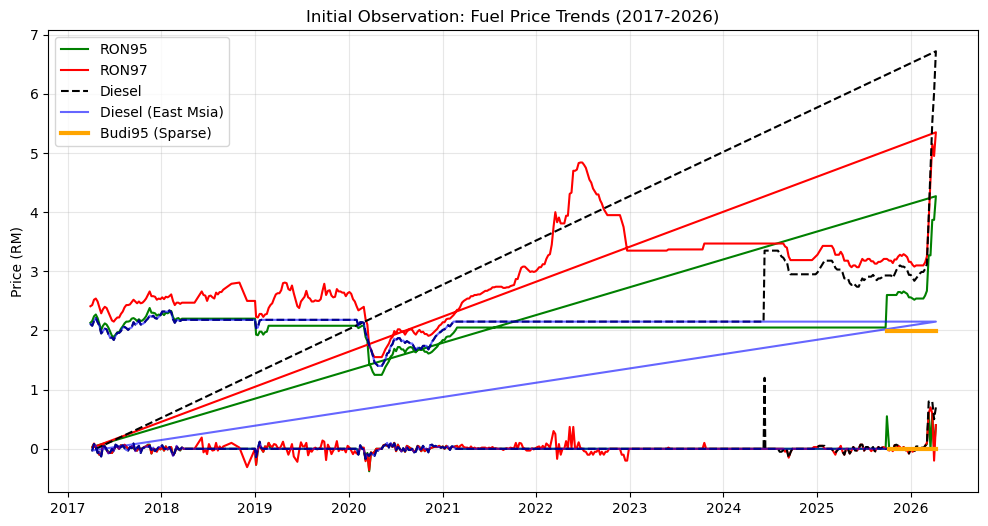

In [8]:
import matplotlib.pyplot as plt

plot_df = df.copy()
plot_df['date'] = pd.to_datetime(plot_df['date'])

# Creating the plot
plt.figure(figsize=(12, 6))

# Plotting the fuels
plt.plot(plot_df['date'], plot_df['ron95'], label='RON95', color='green')
plt.plot(plot_df['date'], plot_df['ron97'], label='RON97', color='red')
plt.plot(plot_df['date'], plot_df['diesel'], label='Diesel', color='black', linestyle='--')
plt.plot(plot_df['date'], plot_df['diesel_eastmsia'], label='Diesel (East Msia)', color='blue', alpha=0.6)
plt.plot(plot_df['date'], plot_df['ron95_budi95'], label='Budi95 (Sparse)', color='orange', linewidth=3)

plt.title("Initial Observation: Fuel Price Trends (2017-2026)")
plt.ylabel("Price (RM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

As shown in the graph, notice how the points are split into two. One group is at ~2.00, and the other group is at ~0.00.  
This clearly showcases anomalies present in our dataset.

**Anomalies**
1. Collective Anomaly 
  - When plotting the raw dataset, a distinct 'Z' shape or zig-zag pattern is visible.
  - This is a collective anomaly, where a group of data points behaves in a way that is **abnormal** for a standard price trend.
  - This pattern is caused by the vertical connection between two unrelated data distributions: the actual price (around RM 2.05) and the weekly change rate (around RM 0.05).
  - To confirm this collective anomaly, the dataset was filtered to examine the `change_weekly` group. The statistics (as shown in the table below) showcase the anomalous graph behavior:

In [9]:
# Filter the data to show only the 'change_weekly' series
change_data = df[df['series_type'] == 'change_weekly']

print("=== Statistics for 'change_weekly' Group ===")
# Show the mean, min, and max for this specific group
print(change_data[['ron95', 'ron97', 'diesel', 'diesel_eastmsia', 'ron95_budi95']].describe().loc[['mean', 'min', 'max']])

print("\n=== Sample of the Collective Anomaly ===")
print(change_data[['date', 'series_type', 'ron95', 'ron97', 'diesel', 'diesel_eastmsia', 'ron95_budi95']].head(5))

=== Statistics for 'change_weekly' Group ===
         ron95     ron97    diesel  diesel_eastmsia  ron95_budi95
mean  0.004703  0.006462  0.010132         0.000088           0.0
min  -0.380000 -0.360000 -0.170000        -0.170000           0.0
max   0.600000  0.700000  1.200000         0.120000           0.0

=== Sample of the Collective Anomaly ===
          date    series_type  ron95  ron97  diesel  diesel_eastmsia  \
456   6/4/2017  change_weekly   0.03   0.02   -0.03            -0.03   
457  13/4/2017  change_weekly   0.08   0.09    0.08             0.08   
458  20/4/2017  change_weekly   0.03   0.02    0.05             0.05   
459  27/4/2017  change_weekly  -0.06  -0.05   -0.07            -0.07   
460   4/5/2017  change_weekly  -0.10  -0.10   -0.06            -0.06   

     ron95_budi95  
456           NaN  
457           NaN  
458           NaN  
459           NaN  
460           NaN  


  - When we isolate the rows where series_type is `change_weekly`, we observe a collective anomaly. As a group, these data points have a mean of nearly 0.00 and stay within a very narrow range (e.g., -0.20 to +0.20).
  - While these values are correct for representing a 'weekly price adjustment,' they are abnormal when treated as part of the general price columns. This group of data deviates entirely from the expected price norm of RM 2.00 – RM 5.00, proving that these rows represent a different mathematical concept than the `level` rows.

2. Contextual Anomalies
  - The Low Price Mean
    - The averages for all fuel types are significantly lower than the historical reality of the Malaysian market.
    - While they are valid numerical values, they are anomalies in the context of Malaysian retail fuel prices, proving the data requires separation.


In [10]:
# Show statistics for the original dataset
print("Mean of Fuel Prices")

print(df[all_fuel].describe().loc[['mean']])

Mean of Fuel Prices
         ron95    ron97    diesel  diesel_eastmsia  ron95_budi95
mean  1.039956  1.48348  1.165862          1.05607      1.013091


  - The 2020 Price Drop
    - A sudden, extreme drop in prices is visible across all fuel types in the year 2020.
    - By checking the minimum values of the level series, we see RON95 hit a low of RM 1.25 in April 2020.
    - Although RM 1.25 would be flagged as an outlier, however this is a verified historical anomaly caused by the Global COVID-19 Pandemic.

In [11]:
# Show 2020 price anomaly
price_levels = df[df['series_type'] == 'level']
print("Lowest Historical Price Levels (2020 Anomaly):")
print(price_levels[['ron95', 'ron97', 'diesel', 'diesel_eastmsia']].min())

Lowest Historical Price Levels (2020 Anomaly):
ron95              1.25
ron97              1.55
diesel             1.40
diesel_eastmsia    1.40
dtype: float64


3. Point Anomalies
  - Impossible Negative Price Values
    - The raw dataset contains negative values which are physically impossible for a commodity price.
    - This happens because the series_type column mixes two different data metrics into one column: absolute prices (`level`) and weekly price adjustments (`change_weekly`).

In [12]:
# Show the negative values
print("Anomalous Minimum Values in Raw Data:")
print(df[['ron95', 'ron97', 'diesel', 'diesel_eastmsia']].min())

Anomalous Minimum Values in Raw Data:
ron95             -0.38
ron97             -0.36
diesel            -0.17
diesel_eastmsia   -0.17
dtype: float64


  - Missing Values in Budi95
    - The ron95_budi95 column is almost entirely empty except appearing at the end of 2025, making it a point anomaly of missingness.
    - Research into the timeline shows this subsidy program (Budi95) was only introduced in late 2025.
    - Because the dataset starts in 2017, this column is missing data for over 90% of the recorded weeks, making it an "incomplete" variable for long-term analysis.

In [13]:
# Show the total missing data rows
budi_nulls = df['ron95_budi95'].isnull().sum()
print(f"Budi95 Missing Values: {budi_nulls} out of {len(df)} rows")

Budi95 Missing Values: 856 out of 911 rows


### Refined Observations (Temporary Filtered Dataset)

C:\Users\Shasha\AppData\Local\Temp\ipykernel_1592\164197480.py:3: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  plot_df['date'] = pd.to_datetime(plot_df['date'])


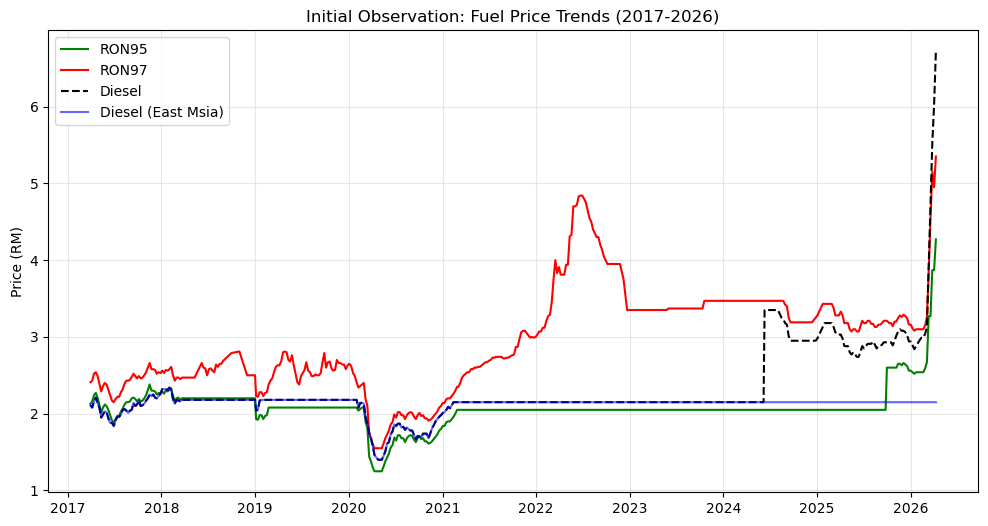

In [14]:
# Temporary filter just for the visual (doesn't change the original df)
plot_df = df_temp.copy()
plot_df['date'] = pd.to_datetime(plot_df['date'])

# Creating the plot
plt.figure(figsize=(12, 6))

# Plotting the main fuels
plt.plot(plot_df['date'], plot_df['ron95'], label='RON95', color='green')
plt.plot(plot_df['date'], plot_df['ron97'], label='RON97', color='red')
plt.plot(plot_df['date'], plot_df['diesel'], label='Diesel', color='black', linestyle='--')
plt.plot(plot_df['date'], plot_df['diesel_eastmsia'], label='Diesel (East Msia)', color='blue', alpha=0.6)

plt.title("Initial Observation: Fuel Price Trends (2017-2026)")
plt.ylabel("Price (RM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

After removing the noise and incomplete variable, the dataset reveals a clear, continuous trend of Malaysian fuel prices.  
 
**Observations**
1. Prices of RON95 and Diesel are mostly flat, straight-line across the period. While global oil prices fluctuate, RON95 and Diesel are capped, showcasing zero volatility.
2. Price of RON97 remains fluctuate, because it is not subsidized by the government. Therefore, its price follows the global market price.
3. During the year 2020, we can see a decline on all fuel prices, representing the economic impact of the Covid-19 pandemic.

This proves that the data is clean enough to reflect real-world historical events accurately.

---
## Section 4 - Data Preprocessing
### 4.1 Handling Missing Values

Before proceeding, performing a check for any null values across all attributes is necessary.

In [15]:
# Check null values in all attributes
print(df.isnull().sum())

series_type          0
date                 0
ron95                0
ron97                0
diesel               0
diesel_eastmsia      0
ron95_budi95       856
dtype: int64


This check confirmed that all fuels are of 0 missing values, except for `ron95_budi95`, proving our previous point anomaly.  
Therefore, `dropna()` is not required. The next step is to drop the `ron95_budi95` column.

In [16]:
# Dropping the column with excessive missing values
df_cleaned = df.drop(columns=['ron95_budi95'])

Justification:
  - As discovered in Step 3, this column is mostly empty.
  - Imputation is impossible because there is no historical data to base it on (the program didn't exist).
  - Removing only the rows with missing values would result in losing almost all our data.
  - Therefore, excluding the column is the only way to maintain the integrity of the primary fuel price analysis.

### 4.2 Handling Noise and Outliers
We identified that most of the noises in our dataset is caused by the `change_weekly` rows.  
Therefore, we need to filter the dataset to keep only series_type == `level`.

In [17]:
# Removing structural noise by keeping only 'level' data
df_preprocessed = df_cleaned[df_cleaned['series_type'] == 'level']

Justification:
  - The `change_weekly` rows represent noise in our dataset as they create a collective anomaly and introduce point anomalies (negative values).
  - By filtering them out, we remove the noise that would affect the mean and variance of our model.
  - Despite the 2020 price drop being a contextual outlier, it is best to retain this data point because it is a verified historical event.

### 4.3 Data Transformation
1. Normalization
   - Apply Min-Max Scaling to all fuel price columns.

In [18]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
cols_to_scale = ['ron95', 'ron97', 'diesel', 'diesel_eastmsia']
df_preprocessed[cols_to_scale] = scaler.fit_transform(df_preprocessed[cols_to_scale])

C:\Users\Shasha\AppData\Local\Temp\ipykernel_1592\1849245694.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_preprocessed[cols_to_scale] = scaler.fit_transform(df_preprocessed[cols_to_scale])


 - Justification:
     - RON97 (up to RM 5.40) and Diesel (RM 2.15) exist on different scales.
     - To ensure we are able to compare values, we scale them to a range of 0 to 1.
     - This prevents the model from being biased toward features with larger values.

C:\Users\Shasha\AppData\Local\Temp\ipykernel_1592\1093032892.py:3: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  plot_df['date'] = pd.to_datetime(plot_df['date'])


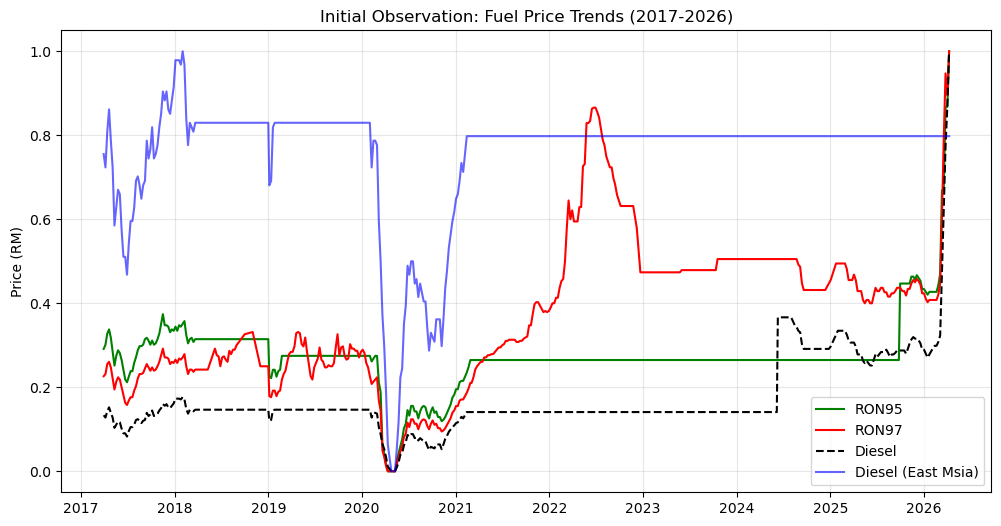

In [19]:
# Pattern after normalization
plot_df = df_preprocessed.copy()
plot_df['date'] = pd.to_datetime(plot_df['date'])

# Creating the plot
plt.figure(figsize=(12, 6))

# Plotting the main fuels
plt.plot(plot_df['date'], plot_df['ron95'], label='RON95', color='green')
plt.plot(plot_df['date'], plot_df['ron97'], label='RON97', color='red')
plt.plot(plot_df['date'], plot_df['diesel'], label='Diesel', color='black', linestyle='--')
plt.plot(plot_df['date'], plot_df['diesel_eastmsia'], label='Diesel (East Msia)', color='blue', alpha=0.6)

plt.title("Initial Observation: Fuel Price Trends (2017-2026)")
plt.ylabel("Price (RM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

  - Format variable `date`
     - As shown in the attribute list, the `date` column is currently stored as an **object** (plain string read by pandas).
     - Convert the `date` column to a standard `datetime64` object.

In [20]:
# Before
print("Before conversion:")
print(df_preprocessed['date'].dtype)

# The Action
df_preprocessed['date'] = pd.to_datetime(df_preprocessed['date'])

# After
print("\nAfter conversion:")
print(df_preprocessed['date'].dtype)

Before conversion:
object

After conversion:
datetime64[ns]


C:\Users\Shasha\AppData\Local\Temp\ipykernel_1592\3842692600.py:6: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_preprocessed['date'] = pd.to_datetime(df_preprocessed['date'])
C:\Users\Shasha\AppData\Local\Temp\ipykernel_1592\3842692600.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_preprocessed['date'] = pd.to_datetime(df_preprocessed['date'])


  - Justification:
    - While modern plotting libraries can often interpret date strings, explicit casting is essential.
    - It ensures that sorting is strictly chronological and allows the dataset to be used for time-series operations that are not possible with plain text strings.

2. Encoding categorical variables
  - While encoding is a standard preprocessing step, it was not required for this specific refined dataset.
  - The only categorical variable, `series_type`, was used to filter noise and was subsequently removed as it became a constant value (`level`) in Step 4.4 Data Cleaning.
  - Therefore, no label encoding was performed to avoid zero variance features that would provide no predictive value.

### 4.4 Data Cleaning
1. Duplicate Data Removal
  - Before proceeding, performing a check on any duplicate data is necessary.

In [21]:
# Check for duplicate rows
duplicate_count = df_preprocessed.duplicated().sum()
print(f"Number of duplicate rows found: {duplicate_count}")

# If duplicates exist, remove them
if duplicate_count > 0:
    df_preprocessed = df_preprocessed.drop_duplicates()
    print("Duplicates removed successfully.")
else:
    print("No duplicates detected. Dataset integrity confirmed.")

Number of duplicate rows found: 0
No duplicates detected. Dataset integrity confirmed.


  - Justification:
      - The check confirms that every row in the dataset is a unique record. 
      - This ensures that no specific week is redundant, which prevents bias during the analysis phase.

2. Irrelevant Data Removal
   - In this case, irrelevant data is the `series_type` column.
   - After filtering `change_weekly`, the column now became a **constant feature**, with only one value and no variance (only `level` records).
   - Thus, we can drop this column.

In [22]:
# Removing the 'series_type' column
df_preprocessed = df_preprocessed.drop(columns=['series_type'])

print("Data Cleaning Complete.")
print(f"Final Features: {df_preprocessed.columns.tolist()}")
print(f"Final Shape: {df_preprocessed.shape}")

Data Cleaning Complete.
Final Features: ['date', 'ron95', 'ron97', 'diesel', 'diesel_eastmsia']
Final Shape: (456, 5)


  - Justification:
    - After the filtering performed in Step 2, the `series_type` column became a constant feature (every row is "level").
    - A variable with zero variance provides no information.
    - Removing it simplifies the dataset and reduces memory usage without losing any meaningful data.

---

## Dataset after Preprocessing

In [23]:
df_preprocessed.head()

,date,ron95,ron97,diesel,diesel_eastmsia
0,2017-03-30,0.291391,0.226316,0.133459,0.755319
1,2017-04-06,0.301325,0.231579,0.127820,0.723404
2,2017-04-13,0.327815,0.255263,0.142857,0.808511
3,2017-04-20,0.337748,0.260526,0.152256,0.861702
4,2017-04-27,0.317881,0.247368,0.139098,0.787234


In [24]:
df_preprocessed.to_csv('cleaned_fuelprice_weekly.csv', index=False)

---
This marks the end of my WIH2001 Individual Assignment. Thank you!